# Task 1 — Collaborative Filtering

**Goal:** Compare two collaborative-filtering approaches on the same interaction data and evaluation protocol:

1. **Memory-based user-user collaborative filtering** using cosine similarity and a weighted-neighborhood predictor.
2. **Model-based matrix factorization** implemented from scratch with SGD, user/item biases, and latent factors.

## Dataset choice
I use the **MovieLens 100K** dataset because it is a stable, widely used benchmark with 100,000 ratings from 1,000 users on roughly 1,700 movies. It is directly a user-item explicit-rating dataset, so both neighborhood methods and matrix factorization are natural fits.

Source: https://lenskit.grouplens.org/datasets/movielens/100k/

The split is **per-user chronological**: for every user, the second-latest rating is validation and the latest rating is test; the remaining ratings are training data. Both models use exactly these same train/validation/test sets. This also avoids training on a user's future interactions when evaluating that user.


In [1]:
# Imports and reproducibility
from pathlib import Path
import urllib.request
import zipfile
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Matplotlib is building the font cache; this may take a moment.


NumPy: 2.5.3
Pandas: 3.0.6


In [2]:
# Download and load MovieLens 100K
DATA_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
CACHE_DIR = Path(".cache") / "movielens_100k"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = CACHE_DIR / "ml-100k.zip"
EXTRACT_DIR = CACHE_DIR / "ml-100k"

if not EXTRACT_DIR.exists():
    if not ZIP_PATH.exists():
        print("Downloading MovieLens 100K...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(CACHE_DIR)

ratings_path = EXTRACT_DIR / "u.data"
ratings = pd.read_csv(
    ratings_path,
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"],
    engine="python",
)
ratings["timestamp"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings = ratings.sort_values(["user_id", "timestamp"]).reset_index(drop=True)

print("Shape:", ratings.shape)
print("Users:", ratings["user_id"].nunique())
print("Items:", ratings["item_id"].nunique())
ratings.head()


Shape: (100000, 4)
Users: 943
Items: 1682


,user_id,item_id,rating,timestamp
0,1,168,5,1997-09-22 21:57:58
1,1,172,5,1997-09-22 21:57:58
2,1,165,5,1997-09-22 21:58:38
3,1,156,4,1997-09-22 21:59:16
4,1,196,5,1997-09-22 22:01:17


In [25]:
# Per-user chronological train/validation/test split
# We keep every user's last two interactions out of training.

train_parts = []
val_parts = []
test_parts = []

for user_id, g in ratings.groupby("user_id", sort=False):
    g = g.sort_values("timestamp")
    if len(g) < 5:
        train_parts.append(g)
    else:
        train_parts.append(g.iloc[:-2])
        val_parts.append(g.iloc[-2:-1])
        test_parts.append(g.iloc[-1:])

train = pd.concat(train_parts, ignore_index=True)
val = pd.concat(val_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

train_item_ids = set(train["item_id"])

val_eval = val[val["item_id"].isin(train_item_ids)].copy()
test_eval = test[test["item_id"].isin(train_item_ids)].copy()

print("Train:", train.shape)
print("Validation:", val.shape, "-> evaluable:", val_eval.shape)
print("Test:", test.shape, "-> evaluable:", test_eval.shape)

print("Validation cold-start item targets removed:",
      len(val) - len(val_eval))
print("Test cold-start item targets removed:",
      len(test) - len(test_eval))


Train: (98114, 4)
Validation: (943, 4) -> evaluable: (941, 4)
Test: (943, 4) -> evaluable: (940, 4)
Validation cold-start item targets removed: 2
Test cold-start item targets removed: 3


## A. Memory-based collaborative filtering

For each user, subtract the user's mean training rating from their observed ratings. Cosine similarity is then computed in this centered user-item space.

For a target user `u` and item `i`, the prediction is:

`mean_u + weighted_average(sim(u,v) * (rating(v,i) - mean_v))`

Only **positive-similarity neighbors who rated the target item** contribute. If none are available, the predictor falls back to the user's training mean. The number of neighbors `k` is selected on the validation set only.


In [26]:
# Build contiguous user/item indices and a dense interaction matrix.
# MovieLens 100K is small enough that a dense matrix is transparent and convenient here.

all_user_ids = np.sort(train["user_id"].unique())
all_item_ids = np.sort(train["item_id"].unique())

user_to_idx = {u: i for i, u in enumerate(all_user_ids)}
item_to_idx = {m: i for i, m in enumerate(all_item_ids)}

R = np.zeros((len(all_user_ids), len(all_item_ids)), dtype=np.float32)
for row in train.itertuples(index=False):
    R[user_to_idx[row.user_id], item_to_idx[row.item_id]] = row.rating

observed = R > 0
user_mean = np.divide(
    R.sum(axis=1),
    observed.sum(axis=1),
    out=np.zeros(R.shape[0], dtype=np.float32),
    where=observed.sum(axis=1) > 0,
)

centered = np.where(observed, R - user_mean[:, None], 0.0).astype(np.float32)
norms = np.linalg.norm(centered, axis=1)

similarity = centered @ centered.T
den = norms[:, None] * norms[None, :]
similarity = np.divide(similarity, den, out=np.zeros_like(similarity), where=den > 0)
np.fill_diagonal(similarity, 0.0)

print("Interaction matrix:", R.shape)
print("Similarity matrix:", similarity.shape)


Interaction matrix: (943, 1677)
Similarity matrix: (943, 943)


In [27]:
def memory_predict_one(user_id, item_id, k=40):
    """Predict one rating with mean-centered user-user neighborhood CF."""
    if user_id not in user_to_idx or item_id not in item_to_idx:
        return float(train["rating"].mean())

    u = user_to_idx[user_id]
    i = item_to_idx[item_id]
    sims = similarity[u].copy()

    candidate_users = np.flatnonzero((sims > 0) & (R[:, i] > 0))
    if candidate_users.size == 0:
        return float(user_mean[u])

    order = candidate_users[np.argsort(sims[candidate_users])[::-1]]
    order = order[:k]
    w = sims[order]
    deviations = R[order, i] - user_mean[order]
    pred = user_mean[u] + np.sum(w * deviations) / (np.sum(np.abs(w)) + 1e-12)
    return float(np.clip(pred, 1.0, 5.0))


def evaluate_memory_rating(df, k=40):
    y_true, y_pred = [], []
    for row in df.itertuples(index=False):
        y_true.append(row.rating)
        y_pred.append(memory_predict_one(row.user_id, row.item_id, k=k))
    y_true = np.asarray(y_true, dtype=np.float32)
    y_pred = np.asarray(y_pred, dtype=np.float32)
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mae = float(np.mean(np.abs(y_true - y_pred)))
    return rmse, mae, y_true, y_pred


k_values = [10, 20, 40, 80]
memory_val_rows = []
for k in k_values:
    rmse, mae, *_ = evaluate_memory_rating(val_eval, k=k)
    memory_val_rows.append({"k": k, "val_RMSE": rmse, "val_MAE": mae})

memory_val_results = pd.DataFrame(memory_val_rows).sort_values("val_RMSE")
memory_val_results


,k,val_RMSE,val_MAE
2,40,1.040218,0.817950
3,80,1.041855,0.817625
1,20,1.043243,0.821617
0,10,1.062242,0.837096


In [28]:
best_k = int(memory_val_results.iloc[0]["k"])
memory_test_rmse, memory_test_mae, memory_y_true, memory_y_pred = evaluate_memory_rating(test_eval, k=best_k)
print(f"Selected k={best_k}")
print(f"Memory-based test RMSE={memory_test_rmse:.4f}, MAE={memory_test_mae:.4f}")


Selected k=40
Memory-based test RMSE=1.0355, MAE=0.8088


In [29]:
def memory_topk_recommendations(user_id, k_neighbors, top_k=10):
    """Return top-k unseen items for a user using neighborhood CF."""
    if user_id not in user_to_idx:
        return []

    u = user_to_idx[user_id]
    sims = similarity[u].copy()
    candidate_users = np.flatnonzero(sims > 0)
    if candidate_users.size == 0:
        scores = user_mean[u] * np.ones(R.shape[1], dtype=np.float32)
    else:
        order = candidate_users[np.argsort(sims[candidate_users])[::-1]][:k_neighbors]
        w = sims[order]
        neighbor_obs = R[order] > 0
        deviations = np.where(neighbor_obs, R[order] - user_mean[order, None], 0.0)
        numerator = (w[:, None] * deviations).sum(axis=0)
        denominator = (np.abs(w)[:, None] * neighbor_obs).sum(axis=0)
        scores = user_mean[u] + np.divide(
            numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0
        )
        scores = np.where(denominator > 0, scores, user_mean[u])

    scores = np.clip(scores, 1.0, 5.0)
    scores[R[u] > 0] = -np.inf
    idx = np.argpartition(scores, -top_k)[-top_k:]
    idx = idx[np.argsort(scores[idx])[::-1]]
    return [all_item_ids[j] for j in idx]


def ranking_metrics_memory(df, k_neighbors=40, top_k=10):
    hits, ndcgs = [], []
    for row in df.itertuples(index=False):
        recs = memory_topk_recommendations(row.user_id, k_neighbors=k_neighbors, top_k=top_k)
        if row.item_id in recs:
            rank = recs.index(row.item_id) + 1
            hits.append(1.0)
            ndcgs.append(1.0 / np.log2(rank + 1))
        else:
            hits.append(0.0)
            ndcgs.append(0.0)
    return float(np.mean(hits)), float(np.mean(ndcgs))

memory_recall10, memory_ndcg10 = ranking_metrics_memory(test_eval, best_k, top_k=10)
print(f"Memory-based Recall@10={memory_recall10:.4f}, NDCG@10={memory_ndcg10:.4f}")


Memory-based Recall@10=0.0064, NDCG@10=0.0027


## B. Model-based collaborative filtering — matrix factorization

We learn:

- user latent vector `p_u`
- item latent vector `q_i`
- user bias `b_u`
- item bias `b_i`

with prediction `global_mean + b_u + b_i + p_u · q_i`.

The implementation below uses vanilla SGD and L2 regularization. There are no pretrained recommendation weights and no end-to-end recommendation library. Hyperparameters are selected using the same validation split as the memory-based method.


In [30]:
def encode_frame(df):
    return (
        df["user_id"].map(user_to_idx).to_numpy(np.int64),
        df["item_id"].map(item_to_idx).to_numpy(np.int64),
        df["rating"].to_numpy(np.float32),
    )

train_u, train_i, train_r = encode_frame(train)
val_u, val_i, val_r = encode_frame(val_eval)
test_u, test_i, test_r = encode_frame(test_eval)


def mf_fit(
    n_users, n_items, u, i, r,
    val_u, val_i, val_r,
    factors=40, lr=0.01, reg=0.05, epochs=25, seed=42,
):
    rng = np.random.default_rng(seed)
    global_mean = float(r.mean())
    bu = np.zeros(n_users, dtype=np.float32)
    bi = np.zeros(n_items, dtype=np.float32)
    pu = (0.05 * rng.standard_normal((n_users, factors))).astype(np.float32)
    qi = (0.05 * rng.standard_normal((n_items, factors))).astype(np.float32)

    history = []
    best_state = None
    best_val = np.inf

    for epoch in range(epochs):
        order = rng.permutation(len(r))
        for idx in order:
            uu = u[idx]
            ii = i[idx]
            rr = r[idx]
            pred = global_mean + bu[uu] + bi[ii] + np.dot(pu[uu], qi[ii])
            err = pred - rr

            old_p = pu[uu].copy()
            pu[uu] -= lr * (err * qi[ii] + reg * pu[uu])
            qi[ii] -= lr * (err * old_p + reg * qi[ii])
            bu[uu] -= lr * (err + reg * bu[uu])
            bi[ii] -= lr * (err + reg * bi[ii])

        val_pred = global_mean + bu[val_u] + bi[val_i] + np.sum(pu[val_u] * qi[val_i], axis=1)
        val_rmse = float(np.sqrt(np.mean((val_r - val_pred) ** 2)))
        train_pred = global_mean + bu[u] + bi[i] + np.sum(pu[u] * qi[i], axis=1)
        train_rmse = float(np.sqrt(np.mean((r - train_pred) ** 2)))
        history.append({"epoch": epoch + 1, "train_RMSE": train_rmse, "val_RMSE": val_rmse})

        if val_rmse < best_val - 1e-5:
            best_val = val_rmse
            best_state = (bu.copy(), bi.copy(), pu.copy(), qi.copy())

    bu, bi, pu, qi = best_state
    return {
        "global_mean": global_mean,
        "bu": bu, "bi": bi, "pu": pu, "qi": qi,
        "history": pd.DataFrame(history),
        "best_val_rmse": best_val,
    }


def mf_predict(model, u, i):
    return np.clip(
        model["global_mean"] + model["bu"][u] + model["bi"][i] + np.sum(model["pu"][u] * model["qi"][i], axis=1),
        1.0, 5.0,
    )


def mf_rank(model, user_id, top_k=10):
    u = user_to_idx[user_id]
    scores = (
        model["global_mean"]
        + model["bu"][u]
        + model["bi"]
        + model["pu"][u] @ model["qi"].T
    ).astype(np.float32)
    scores[R[u] > 0] = -np.inf
    idx = np.argpartition(scores, -top_k)[-top_k:]
    idx = idx[np.argsort(scores[idx])[::-1]]
    return [all_item_ids[j] for j in idx]


def ranking_metrics_mf(df, model, top_k=10):
    hits, ndcgs = [], []
    for row in df.itertuples(index=False):
        recs = mf_rank(model, row.user_id, top_k=top_k)
        if row.item_id in recs:
            rank = recs.index(row.item_id) + 1
            hits.append(1.0)
            ndcgs.append(1.0 / np.log2(rank + 1))
        else:
            hits.append(0.0)
            ndcgs.append(0.0)
    return float(np.mean(hits)), float(np.mean(ndcgs))


In [31]:
# Small validation sweep. Increase epochs only if you have time.
MF_CONFIGS = [
    {"factors": 20, "lr": 0.01, "reg": 0.05, "epochs": 25},
    {"factors": 40, "lr": 0.01, "reg": 0.05, "epochs": 25},
]

mf_runs = []
for cfg in MF_CONFIGS:
    start = time.perf_counter()
    model = mf_fit(
        len(all_user_ids), len(all_item_ids),
        train_u, train_i, train_r,
        val_u, val_i, val_r,
        seed=SEED, **cfg
    )
    elapsed = time.perf_counter() - start
    mf_runs.append({
        **cfg,
        "val_RMSE": model["best_val_rmse"],
        "seconds": elapsed,
        "model": model,
    })

mf_sweep = pd.DataFrame([{k:v for k,v in x.items() if k != "model"} for x in mf_runs])
mf_sweep


,factors,lr,reg,epochs,val_RMSE,seconds
0,20,0.01,0.05,25,1.016688,9.852165
1,40,0.01,0.05,25,1.015353,9.739847


In [32]:
best_mf_run = min(mf_runs, key=lambda x: x["val_RMSE"])
best_mf = best_mf_run["model"]

mf_test_pred = mf_predict(best_mf, test_u, test_i)
mf_test_rmse = float(np.sqrt(np.mean((test_r - mf_test_pred) ** 2)))
mf_test_mae = float(np.mean(np.abs(test_r - mf_test_pred)))
mf_recall10, mf_ndcg10 = ranking_metrics_mf(test, best_mf, top_k=10)

print(f"Selected factors={best_mf_run['factors']}")
print(f"Matrix factorization test RMSE={mf_test_rmse:.4f}, MAE={mf_test_mae:.4f}")
print(f"Matrix factorization Recall@10={mf_recall10:.4f}, NDCG@10={mf_ndcg10:.4f}")


Selected factors=40
Matrix factorization test RMSE=1.0111, MAE=0.7917
Matrix factorization Recall@10=0.0191, NDCG@10=0.0083


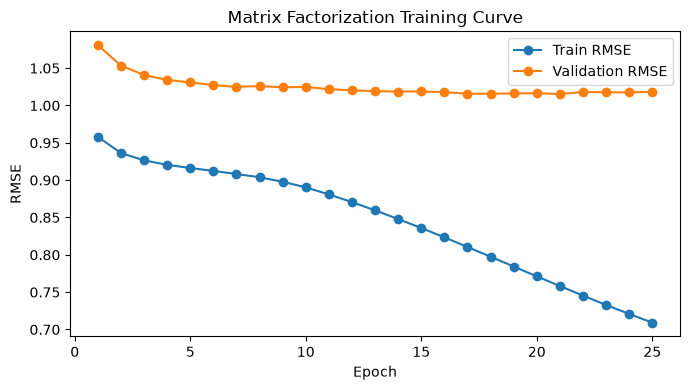

In [33]:
# Training curve for the selected matrix-factorization configuration.
hist = best_mf["history"]
plt.figure(figsize=(7, 4))
plt.plot(hist["epoch"], hist["train_RMSE"], marker="o", label="Train RMSE")
plt.plot(hist["epoch"], hist["val_RMSE"], marker="o", label="Validation RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Matrix Factorization Training Curve")
plt.legend()
plt.tight_layout()
plt.show()


In [34]:
# Final comparison table — same test set for both models.
results = pd.DataFrame([
    {
        "Model": "Memory-based user-user CF",
        "RMSE": memory_test_rmse,
        "MAE": memory_test_mae,
        "Recall@10": memory_recall10,
        "NDCG@10": memory_ndcg10,
    },
    {
        "Model": "Matrix factorization",
        "RMSE": mf_test_rmse,
        "MAE": mf_test_mae,
        "Recall@10": mf_recall10,
        "NDCG@10": mf_ndcg10,
    },
])
results


,Model,RMSE,MAE,Recall@10,NDCG@10
0,Memory-based user-user CF,1.035545,0.808837,0.006383,0.002684
1,Matrix factorization,1.011115,0.791672,0.019088,0.008340


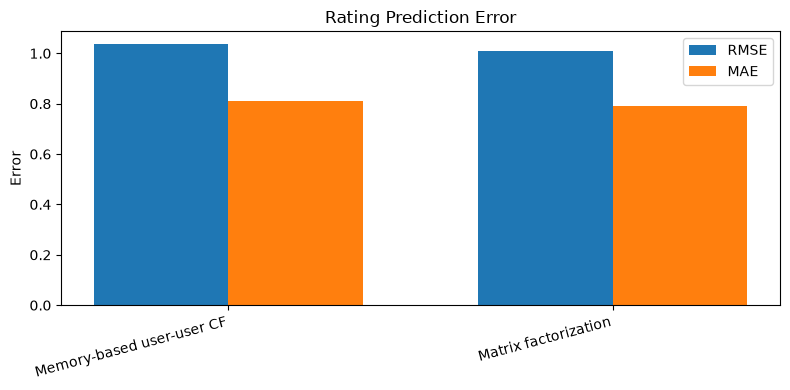

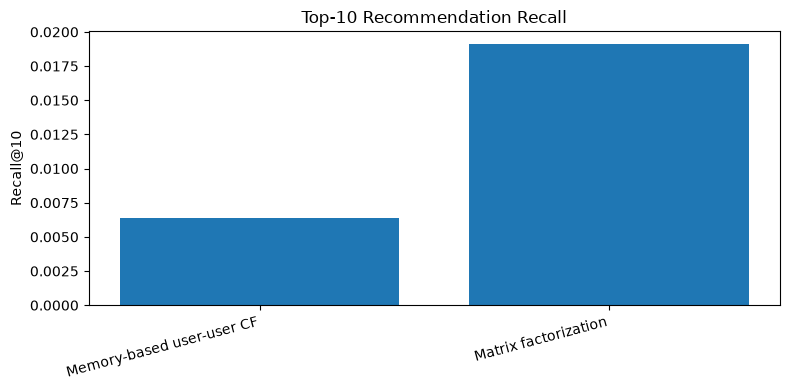

In [35]:
# Comparison plots required by the task.
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(results))
width = 0.35
ax.bar(x - width/2, results["RMSE"], width, label="RMSE")
ax.bar(x + width/2, results["MAE"], width, label="MAE")
ax.set_xticks(x)
ax.set_xticklabels(results["Model"], rotation=15, ha="right")
ax.set_ylabel("Error")
ax.set_title("Rating Prediction Error")
ax.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(results["Model"], results["Recall@10"])
plt.ylabel("Recall@10")
plt.title("Top-10 Recommendation Recall")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## Conclusion template — fill this after running

Report the **measured** numbers from the final table rather than inventing expected values. A useful conclusion should cover:

- Which method had lower RMSE/MAE on this split.
- Which method had higher Recall@10/NDCG@10.
- Memory-based CF: easy to explain, no model training, directly uses neighborhood behavior, but prediction cost and coverage can become problematic as the user/item population grows and as sparse neighborhoods become thinner.
- Matrix factorization: compresses users/items into low-dimensional factors, so it can generalize beyond direct nearest-neighbor overlap, while introducing training cost, hyperparameters, and latent factors that are less directly interpretable.

Do not claim one approach is universally better. Tie the conclusion to the observed metrics and the operating conditions.
